# Exportations agroalimentaires marocaines : prévoir les ventes de fruits par marché

**Projet n° 12 — Data Science appliquée au commerce international**
Binôme : *[Étudiant 1]* / *[Étudiant 2]* — Année universitaire 2026–2027

**Question de recherche.** Comment prévoir la valeur annuelle des exportations
marocaines de fruits (chapitre 08 du Système harmonisé) vers chacun de leurs
marchés européens, et que nous apprennent les données sur la structure de ces
marchés ?

**Données.** UN Comtrade, API publique *preview*, extraction du 31/10/2026 :
Maroc (504), flux exportations (X), chapitre HS 08 décomposé en 14 positions
HS4, six marchés (France, Espagne, Allemagne, Pays-Bas, Royaume-Uni, Italie),
2010–2024.

**Principe de travail.** Aucune donnée n'est inventée. Toutes les valeurs
affichées proviennent de l'API et sont reproductibles via `src/download_comtrade.py`
puis `src/prepare_data.py`. La validation est strictement temporelle.

## 0. Sommaire et démarche

| Section | Contenu | Livrable |
|---|---|---|
| 1 | Problématique et hypothèses | Question de recherche |
| 2 | Accès aux données et licence | URL + journal d'extraction |
| 3 | Chargement | Dimensions observées |
| 4 | Dictionnaire des variables | Types, unités, rôles |
| 5 | Qualité et nettoyage | Journal des transformations |
| 6 | Analyse exploratoire | 5 figures commentées (jalon 1) |
| 7 | Construction des variables | Cible et retards sans fuite |
| 8 | Découpage temporel | Fenêtres glissantes |
| 9 | Modèle de référence | Persistance |
| 10–11 | Modèles alternatifs et hyperparamètres | Ridge, forêt aléatoire, gradient boosting |
| 12 | Évaluation hors échantillon | Tableau comparatif (jalon 2) |
| 13 | Sensibilité et interprétation | Importance, tests de robustesse |
| 14 | Conclusion commerciale | Projection 2025 |
| 15 | Reproductibilité | Versions, graine, fichiers |

In [1]:
# --- Bibliothèques et configuration -----------------------------------------
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

GRAINE = 42
np.random.seed(GRAINE)

# Dossiers : le notebook vit dans notebooks/, les données dans ../data
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = RACINE / "data" / "processed"
FIGURES = RACINE / "figures"
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.autolayout": False,
})

# Palette accessible (daltonisme) et stable dans tout le document
PALETTE = ["#0B6E4F", "#1F4E79", "#C1440E", "#6A4C93", "#B8860B",
           "#2A9D8F", "#A23B72", "#4D4D4D", "#8FBF6A"]
COULEUR_REF = "#6B7280"
COURT = {
    "0802": "Fruits à coque", "0804": "Dattes, avocats", "0805": "Agrumes",
    "0806": "Raisins", "0807": "Melons, pastèques", "0809": "Abricots, cerises",
    "0810": "Autres fruits frais", "0811": "Fruits congelés",
    "0814": "Écorces d'agrumes",
}

print("Versions : numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", plt.matplotlib.__version__)
print("Racine du projet :", RACINE)

Versions : numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2
Racine du projet : /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc


## 1. Problématique, hypothèses et objectifs

### 1.1 Contexte économique

Le Maroc a fait de l'agroalimentaire un pilier de ses exportations : le
chapitre 08 du Système harmonisé (fruits comestibles, agrumes, fruits à coque)
est l'un des premiers postes exportés vers l'Union européenne. La proximité
géographique, les accords de libre-échange (accord d'association UE–Maroc) et
la saisonnalité inverse de l'hémisphère nord expliquent la position du pays sur
les marchés français, britannique et néerlandais. La filière est toutefois
exposée à trois risques : la concentration sur quelques marchés, la volatilité
des prix et la concurrence espagnole sur les agrumes.

### 1.2 Question de recherche et hypothèses

**Question.** Peut-on prévoir, à un horizon d'un an, la valeur exportée d'un
couple (marché, produit) et dépasser une prévision naïve ?

- **H1 — Persistance.** Les valeurs exportées se comportent comme une marche
  aléatoire : la meilleure prévision de l'année *t+1* est la valeur de l'année
  *t*. Les modèles d'apprentissage ne doivent pas la battre systématiquement.
- **H2 — Structure.** La valeur totale progresse, mais la composition par
  produit et par marché se déplace (montée des fruits hors agrumes, recul
  relatif de la France).
- **H3 — Prix.** Une partie de la croissance est une croissance en valeur
  (prix unitaires), et non en volume.

### 1.3 Objectifs mesurables

1. Constituer un panel reproductible de 6 marchés × 14 produits HS4 × 15 années.
2. Comparer trois familles de modèles à une référence naïve sous validation
   temporelle stricte (MAE, RMSE, WAPE).
3. Produire une projection 2025 par marché, assortie d'un intervalle et de
   réserves explicites.

## 2. Accès aux données : source, licence et quotas

| Élément | Valeur |
|---|---|
| Producteur | Division statistique des Nations unies (UNSD) |
| Jeu de données | UN Comtrade — *International Trade Statistics* |
| API | `https://comtradeapi.un.org/public/v1/preview/C/A/HS` |
| Documentation | https://uncomtrade.org/docs/un-comtrade-api/ |
| Licence | Conditions d'utilisation UN Comtrade (citation obligatoire, usage non commercial pour l'aperçu public) |
| Déclarant | Maroc (code 504) — les séries sont donc déclarées, non miroir |
| Flux | Exportations (`flowCode=X`) |
| Produits | HS 08 et positions HS4 0801 à 0814 (classification H6) |
| Partenaires | France 251, Espagne 724, Allemagne 276, Pays-Bas 528, Royaume-Uni 826, Italie 380 ; Monde 0 pour les totaux |
| Période | 2010–2024, fréquence annuelle |
| Contraintes constatées le 31/10/2026 | 1 période par requête en mode aperçu ; 500 lignes maximum par réponse ; pas de clé d'API |

Le script `src/download_comtrade.py` effectue 45 requêtes (15 années × 3
extractions), sauvegarde chaque réponse JSON brute et journalise l'URL, le
statut HTTP et le nombre de lignes. Le journal est conservé dans
`data/processed/journal_extractions.csv` : c'est la preuve de traçabilité
exigée par le guide.

In [2]:
# --- Vérification de la présence des fichiers et du journal d'extraction ----
fichiers = {
    "brut": DATA / "comtrade_brut.csv",
    "panel": DATA / "panel.csv",
    "series": DATA / "series_annuelles.csv",
    "qualite": DATA / "qualite.csv",
    "journal": DATA / "journal_extractions.csv",
}
for nom, chemin in fichiers.items():
    print(f"{nom:8s} : {'OK' if chemin.exists() else 'MANQUANT'}  {chemin}")

journal = pd.read_csv(fichiers["journal"])
print("\nRequêtes journalisées :", len(journal))
print("Statuts :", journal["statut"].value_counts().to_dict())
print("Lignes téléchargées :", int(journal["nb_lignes"].sum()))
print("Première requête :", journal.loc[0, "url"])
print("Horodatage (UTC) :", journal.loc[0, "horodatage_utc"])

brut     : OK  /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/comtrade_brut.csv
panel    : OK  /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/panel.csv
series   : OK  /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/series_annuelles.csv
qualite  : OK  /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/qualite.csv
journal  : OK  /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/journal_extractions.csv

Requêtes journalisées : 45
Statuts : {'ok': 45}
Lignes téléchargées : 1058
Première requête : https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=504&period=2010&partnerCode=251,724,276,528,826,380&cmdCode=0801,0802,0803,0804,0805,0806,0807,0808,0809,0810,0811,0812,0813,0814&flowCode=X
Horodatage (UTC) : 2026-10-31T15:25:19+00:00


## 3. Chargement et dimensions effectives

Les dimensions ne sont pas supposées : elles sont **comptées** après
téléchargement. Le panel est une grille complète (partenaire × produit × année) ;
les cellules absentes de l'API sont explicitées par la colonne `declare`.

In [3]:
brut = pd.read_csv(fichiers["brut"], dtype={"cmdCode": str})
brut["cmdCode"] = brut["cmdCode"].str.zfill(4)
panel = pd.read_csv(fichiers["panel"], dtype={"cmdCode": str})
panel["cmdCode"] = panel["cmdCode"].str.zfill(4)
series = pd.read_csv(fichiers["series"])
qualite = pd.read_csv(fichiers["qualite"], dtype={"cmdCode": str})
qualite["cmdCode"] = qualite["cmdCode"].str.zfill(4)

print("Réponses brutes   :", brut.shape, "| colonnes :", list(brut.columns))
print("Panel analytique  :", panel.shape)
print("Séries annuelles  :", series.shape)
print("Années            :", panel.annee.min(), "à", panel.annee.max())
print("Marchés           :", panel.partnerLibelle.nunique())
print("Produits HS4      :", panel.cmdCode.nunique())
print("Cellules observées:", int(panel.declare.sum()), "/", len(panel),
      f"({panel.declare.mean():.1%})")

display(panel.head(8))

Réponses brutes   : (1058, 15) | colonnes : ['period', 'refYear', 'reporterCode', 'flowCode', 'partnerCode', 'cmdCode', 'aggrLevel', 'primaryValue', 'netWgt', 'qty', 'qtyUnitAbbr', 'classificationCode', 'isAggregate', 'partnerLibelle', 'extraction']
Panel analytique  : (1260, 12)
Séries annuelles  : (15, 6)
Années            : 2010 à 2024
Marchés           : 6
Produits HS4      : 14
Cellules observées: 834 / 1260 (66.2%)


,partnerCode,cmdCode,annee,partnerLibelle,valeur_usd,poids_net_kg,declare,monde_usd,produit,part_marche,prix_unitaire_usd_kg,retenu_pour_modele
0,276,0801,2010,Allemagne,0.000,0.000,0,"1,819.000","Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
1,276,0801,2011,Allemagne,3.000,8.000,1,"32,020.000","Noix de coco, noix du Brésil et noix de cajou",0.000,0.375,0
2,276,0801,2012,Allemagne,0.000,0.000,0,"40,681.000","Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
3,276,0801,2013,Allemagne,0.000,0.000,0,"2,699.000","Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
4,276,0801,2014,Allemagne,0.000,0.000,0,"1,065.000","Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
5,276,0801,2015,Allemagne,0.000,0.000,0,295.244,"Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
6,276,0801,2016,Allemagne,0.000,0.000,0,841.000,"Noix de coco, noix du Brésil et noix de cajou",0.000,NaN,0
7,276,0801,2017,Allemagne,0.000,0.000,0,NaN,"Noix de coco, noix du Brésil et noix de cajou",NaN,NaN,0


## 4. Dictionnaire des variables

| Variable | Type | Unité | Rôle |
|---|---|---|---|
| `annee` | entier | année | index temporel |
| `partnerCode` / `partnerLibelle` | entier / texte | code ONU / libellé | marché de destination |
| `cmdCode` / `produit` | texte / texte | code HS4 / libellé | produit exporté |
| `valeur_usd` | réel | USD courants | variable expliquée (niveau) |
| `poids_net_kg` | réel | kilogrammes | volume déclaré, sert au prix unitaire |
| `prix_unitaire_usd_kg` | réel | USD / kg | prix implicite |
| `monde_usd` | réel | USD courants | exportations marocaines du produit vers le monde |
| `part_marche` | réel | 0–1 | poids du marché dans les exportations du produit |
| `declare` | 0/1 | indicatrice | 1 = cellule observée dans Comtrade, 0 = zéro imputé |
| `retenu_pour_modele` | 0/1 | indicatrice | produit suffisamment couvert (≥ 50 %) |
| `log_v`, `log_v_lag1`, `log_v_lag2`, `croissance`, `moy3` | réel | log(1+USD) | variables construites (section 7) |
| `cible` / `cible_log` | réel | USD / log(1+USD) | valeur exportée en *t+1* |

Les unités monétaires sont des **dollars courants** : aucune déflation n'est
appliquée, ce qui constitue une limite explicite (section 13).

In [4]:
# --- Contrôles de qualité ---------------------------------------------------
controles = pd.DataFrame({
    "controle": [
        "Doublons (marché, produit, année)",
        "Valeurs négatives",
        "Valeurs nulles observées",
        "Cellules imputées à zéro",
        "Poids net manquant sur cellules observées",
        "Somme HS4 vs total HS2 (2024, écart relatif)",
    ],
    "resultat": pd.Series([
        int(panel.duplicated(["partnerCode", "cmdCode", "annee"]).sum()),
        int((panel.valeur_usd < 0).sum()),
        int((panel.valeur_usd == 0).sum()),
        int((panel.declare == 0).sum()),
        int(panel.loc[panel.declare == 1, "poids_net_kg"].isna().sum()),
        None,
    ], dtype="object"),
})

# Cohérence interne : la somme des HS4 doit retrouver le total HS2 du chapitre
somme_hs4 = (
    panel[panel.annee == 2024].groupby("annee")["valeur_usd"].sum().iloc[0]
)
total_hs2 = brut.query("extraction == 'monde_hs2' and period == 2024")["primaryValue"].sum()
controles.loc[5, "resultat"] = f"{abs(somme_hs4 / total_hs2 - 1):.1%}"
display(controles)

print("\nCouverture par produit (règle R3 : seuil 50 %) :")
display(qualite.sort_values("taux_couverture", ascending=False).round(3))

print("\nJournal des transformations :")
journal_transformations = [
    "1. Code produit lu en chaîne sur 4 caractères (0805 et non 805).",
    "2. Grille complète partenaire x produit x année ; absence = flux nul (R2).",
    "3. Colonne `declare` conservée pour tester l'effet des zéros imputés.",
    "4. Produits sous 50 % de couverture écartés du modèle (R3), gardés en base.",
    "5. Aucune déflation : les valeurs restent en USD courants.",
    "6. Aucun doublon, aucune valeur négative : rien à supprimer.",
]
print("\n".join(journal_transformations))

,controle,resultat
0,"Doublons (marché, produit, année)",0
1,Valeurs négatives,0
2,Valeurs nulles observées,426
3,Cellules imputées à zéro,426
4,Poids net manquant sur cellules observées,0
5,"Somme HS4 vs total HS2 (2024, écart relatif)",24.4%



Couverture par produit (règle R3 : seuil 50 %) :


,cmdCode,produit,cellules_observees,cellules_totales,taux_couverture,valeur_totale_usd,retenu_pour_modele
10,0811,Fruits congelés,90,90,1.000,"1,133,434,968.794",1
6,0807,"Melons, pastèques et papayes",90,90,1.000,"1,983,373,339.968",1
5,0806,Raisins frais ou secs,87,90,0.967,"136,424,614.891",1
4,0805,Agrumes (frais ou secs),86,90,0.956,"2,471,761,419.700",1
9,0810,"Autres fruits frais (fraises, kiwis, grenades)",83,90,0.922,"5,217,233,391.524",1
3,0804,"Dattes, figues, ananas, avocats, mangues",79,90,0.878,"933,901,740.920",1
1,0802,"Autres fruits à coque (amandes, noisettes, noix)",76,90,0.844,"49,581,176.273",1
8,0809,"Abricots, cerises, pêches, prunes",59,90,0.656,"91,959,073.822",1
13,0814,Écorces d'agrumes ou de melons,53,90,0.589,"5,713,464.514",1
11,0812,Fruits conservés provisoirement,39,90,0.433,"3,194,132.720",0



Journal des transformations :
1. Code produit lu en chaîne sur 4 caractères (0805 et non 805).
2. Grille complète partenaire x produit x année ; absence = flux nul (R2).
3. Colonne `declare` conservée pour tester l'effet des zéros imputés.
4. Produits sous 50 % de couverture écartés du modèle (R3), gardés en base.
5. Aucune déflation : les valeurs restent en USD courants.
6. Aucun doublon, aucune valeur négative : rien à supprimer.


## 5. Analyse exploratoire — cinq figures commentées

Chaque figure est enregistrée dans `figures/` et commentée juste après. Les
montants sont en millions de dollars courants (M USD).

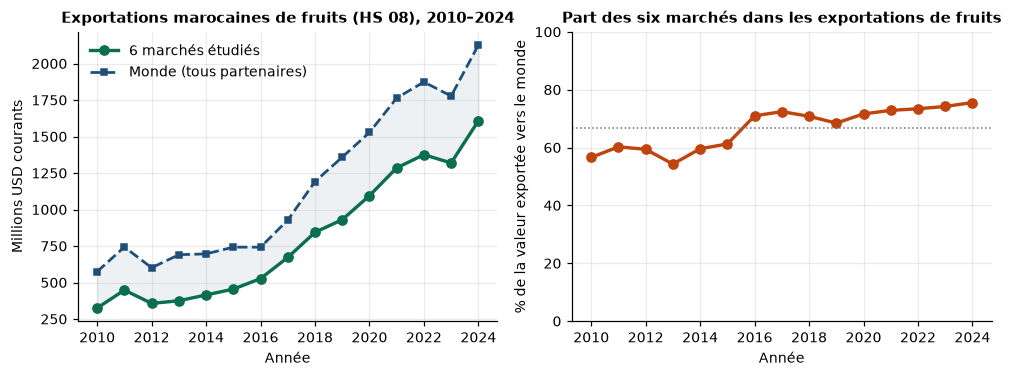

Valeur 2024 vers les 6 marchés : 1,608 M USD
Croissance 2010-2024           : 4.94 x
TCAM 2010-2024                 : 12.1%
Part moyenne des 6 marchés     : 66.8%


In [5]:
# --- Figure 1 : dynamique agrégée et poids dans les exportations mondiales --
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5))

ax = axes[0]
ax.plot(series.annee, series.valeur_6_marches_usd / 1e6, marker="o",
        color=PALETTE[0], lw=2.2, label="6 marchés étudiés")
ax.plot(series.annee, series.valeur_monde_usd / 1e6, marker="s", ms=4,
        color=PALETTE[1], lw=1.8, ls="--", label="Monde (tous partenaires)")
ax.fill_between(series.annee, series.valeur_6_marches_usd / 1e6,
                series.valeur_monde_usd / 1e6, color=PALETTE[1], alpha=0.08)
ax.set_title("Exportations marocaines de fruits (HS 08), 2010–2024")
ax.set_xlabel("Année")
ax.set_ylabel("Millions USD courants")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
ax.plot(series.annee, 100 * series.part_6_marches, marker="o",
        color=PALETTE[2], lw=2.2)
ax.axhline(series.part_6_marches.mean() * 100, color=COULEUR_REF, ls=":", lw=1)
ax.set_title("Part des six marchés dans les exportations de fruits")
ax.set_xlabel("Année")
ax.set_ylabel("% de la valeur exportée vers le monde")
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(FIGURES / "fig01_dynamique_agregee.png")
plt.show()

print(f"Valeur 2024 vers les 6 marchés : {series.valeur_6_marches_usd.iloc[-1]/1e6:,.0f} M USD")
print(f"Croissance 2010-2024           : {series.valeur_6_marches_usd.iloc[-1]/series.valeur_6_marches_usd.iloc[0]:.2f} x")
print(f"TCAM 2010-2024                 : {((series.valeur_6_marches_usd.iloc[-1]/series.valeur_6_marches_usd.iloc[0])**(1/14)-1):.1%}")
print(f"Part moyenne des 6 marchés     : {series.part_6_marches.mean():.1%}")

**Lecture de la figure 1.** La valeur exportée vers les six marchés passe de
326 M USD en 2010 à 1 608 M USD en 2024, soit une multiplication par 4,9 et un
taux de croissance annuel moyen de 12,1 %. La progression est continue, avec une
accélération nette après 2017 et un plateau en 2023 (recul de la demande
européenne et effet de base après la flambée de 2022). Les six marchés captent
56,6 % des exportations marocaines de fruits en 2010 et 75,6 % en 2024
(66,8 % en moyenne sur la période) : la zone étudiée est donc représentative,
mais la dépendance à l'Europe constitue un risque de concentration.

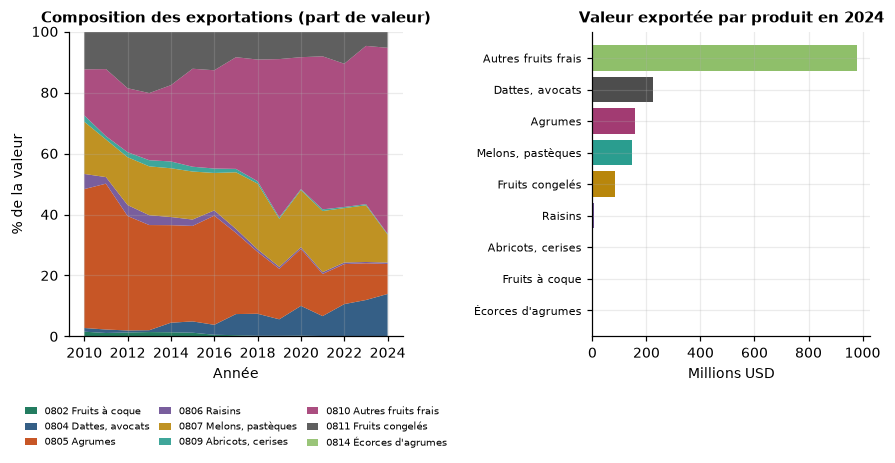

Top 3 produits en 2024 (M USD) :
cmdCode
0810   980.300
0804   222.900
0805   158.000


In [6]:
# --- Figure 2 : structure par produit --------------------------------------
par_produit = (
    panel[panel.retenu_pour_modele == 1]
    .groupby(["annee", "cmdCode"])["valeur_usd"].sum().unstack(fill_value=0)
)
part = par_produit.div(par_produit.sum(axis=1), axis=0) * 100

fig = plt.figure(figsize=(9.4, 4.4))
grille = fig.add_gridspec(1, 2, width_ratios=[1.2, 1], wspace=0.62)
ax = fig.add_subplot(grille[0])
ax.stackplot(part.index, [part[c] for c in part.columns],
             labels=[f"{c} {COURT[c]}" for c in part.columns],
             colors=PALETTE[: len(part.columns)], alpha=0.9)
ax.set_title("Composition des exportations (part de valeur)")
ax.set_xlabel("Année")
ax.set_ylabel("% de la valeur")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3,
          fontsize=6.4, frameon=False, handlelength=1.2, columnspacing=1.0)

ax = fig.add_subplot(grille[1])
top = par_produit.loc[2024].sort_values(ascending=True).tail(9)
ax.barh(range(len(top)), top.values / 1e6,
        color=[PALETTE[i % len(PALETTE)] for i in range(len(top))])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([COURT[c] for c in top.index], fontsize=7.5)
ax.set_title("Valeur exportée par produit en 2024")
ax.set_xlabel("Millions USD")
fig.subplots_adjust(bottom=0.27, top=0.90)
fig.savefig(FIGURES / "fig02_structure_produits.png")
plt.show()

print("Top 3 produits en 2024 (M USD) :")
print((par_produit.loc[2024].sort_values(ascending=False).head(3) / 1e6).round(1).to_string())

**Lecture de la figure 2.** La structure est dominée par les « autres fruits
frais » (HS 0810 : fraises, kiwis, grenades), qui représentent 61,0 % de la
valeur en 2024, devant les dattes et avocats (0804, 13,9 %), les agrumes (0805,
9,8 %) et les melons et pastèques (0807, 9,2 %). Les agrumes, produit
emblématique de la fiche projet, ne représentent donc qu'un dixième de la
valeur du chapitre : la question « prévoir les exportations d'agrumes » doit
être traitée comme un cas particulier d'un système plus large, ce qui justifie
de modéliser le panel produit × marché plutôt qu'une série isolée.

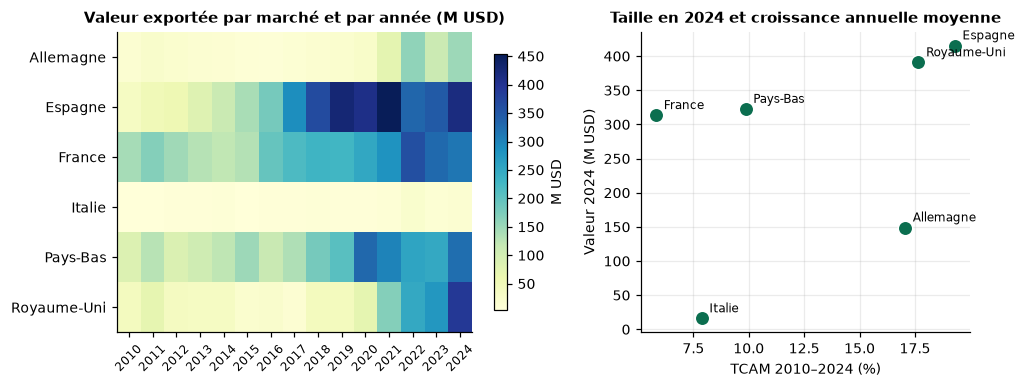

Valeur 2024 et TCAM par marché :


,valeur_2024_M,TCAM_%,part_2024_%
partnerLibelle,,,
Espagne,415.600,19.300,25.900
Royaume-Uni,390.900,17.700,24.300
Pays-Bas,322.600,9.900,20.100
France,313.500,5.800,19.500
Allemagne,149.000,17.100,9.300
Italie,15.900,7.900,1.000


In [7]:
# --- Figure 3 : marchés, niveau et dynamique ---------------------------------
pivot = panel.pivot_table(index="partnerLibelle", columns="annee",
                          values="valeur_usd", aggfunc="sum") / 1e6
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6),
                         gridspec_kw={"width_ratios": [1.35, 1]})

ax = axes[0]
im = ax.imshow(pivot.values, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, fontsize=8)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=9)
ax.set_title("Valeur exportée par marché et par année (M USD)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="M USD")

ax = axes[1]
v2024 = pivot[2024].sort_values()
cagr = (pivot[2024] / pivot[2010]) ** (1 / 14) - 1
ax.scatter(cagr[v2024.index] * 100, v2024.values, s=90,
           color=PALETTE[0], edgecolor="white", zorder=3)
for marche in v2024.index:
    ax.annotate(marche, (cagr[marche] * 100, v2024[marche]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_title("Taille en 2024 et croissance annuelle moyenne")
ax.set_xlabel("TCAM 2010–2024 (%)")
ax.set_ylabel("Valeur 2024 (M USD)")
fig.tight_layout()
fig.savefig(FIGURES / "fig03_marches.png")
plt.show()

print("Valeur 2024 et TCAM par marché :")
recap = pd.DataFrame({"valeur_2024_M": pivot[2024].round(1),
                      "TCAM_%": (cagr * 100).round(1),
                      "part_2024_%": (100 * pivot[2024] / pivot[2024].sum()).round(1)})
display(recap.sort_values("valeur_2024_M", ascending=False))

**Lecture de la figure 3.** Quatre marchés concentrent l'essentiel de la
valeur en 2024 : l'Espagne (415,6 M USD), le Royaume-Uni (390,9 M USD), les
Pays-Bas (322,6 M USD) et la France (313,5 M USD), devant l'Allemagne
(149,0 M USD) et l'Italie (15,9 M USD). Les trajectoires divergent fortement :
sur 2010–2024, l'Espagne (+19,3 % par an) et le Royaume-Uni (+17,7 %) portent la
croissance, tandis que la France, premier marché en 2010 (142,0 M USD), ne
progresse que de 5,8 % par an et perd des parts. Les Pays-Bas jouent un rôle de
hub de réexportation (Rotterdam), ce qui gonfle leur poids dans les statistiques
de destination.

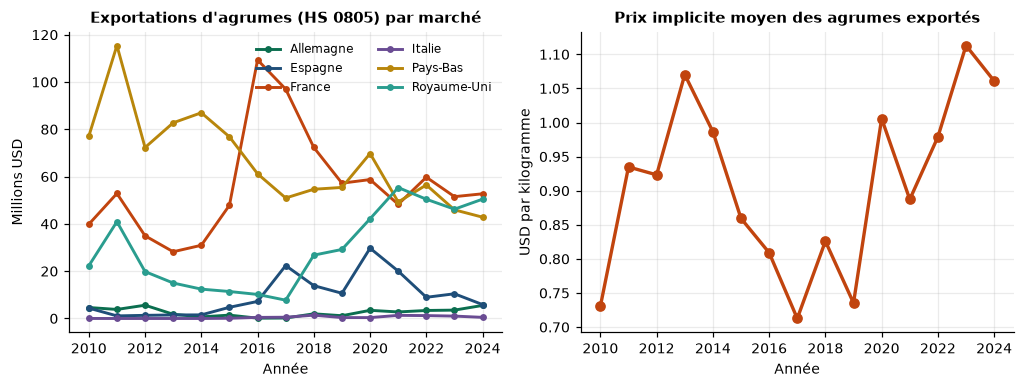

Prix implicite 2010 : 0.73 USD/kg | 2024 : 1.06 USD/kg
Évolution : +45.2%

Part de chaque marché dans les agrumes 2024 (%) :
partnerLibelle
Allemagne      3.500
Espagne        3.700
France        33.400
Italie         0.300
Pays-Bas      27.100
Royaume-Uni   32.000


In [8]:
# --- Figure 4 : agrumes par marché et prix implicite ------------------------
agrumes = panel[panel.cmdCode == "0805"]
pivot_agr = agrumes.pivot_table(index="annee", columns="partnerLibelle",
                               values="valeur_usd", aggfunc="sum") / 1e6

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
ax = axes[0]
for i, marche in enumerate(pivot_agr.columns):
    ax.plot(pivot_agr.index, pivot_agr[marche], marker="o", ms=3.5,
            lw=1.9, color=PALETTE[i % len(PALETTE)], label=marche)
ax.set_title("Exportations d'agrumes (HS 0805) par marché")
ax.set_xlabel("Année")
ax.set_ylabel("Millions USD")
ax.legend(frameon=False, fontsize=8, ncol=2)

ax = axes[1]
prix = (agrumes.groupby("annee")
        .apply(lambda d: d.valeur_usd.sum() / d.poids_net_kg.sum(), include_groups=False))
ax.plot(prix.index, prix.values, marker="o", color=PALETTE[2], lw=2.2)
ax.set_title("Prix implicite moyen des agrumes exportés")
ax.set_xlabel("Année")
ax.set_ylabel("USD par kilogramme")
fig.tight_layout()
fig.savefig(FIGURES / "fig04_agrumes.png")
plt.show()

print(f"Prix implicite 2010 : {prix.iloc[0]:.2f} USD/kg | 2024 : {prix.iloc[-1]:.2f} USD/kg")
print(f"Évolution : {prix.iloc[-1]/prix.iloc[0]-1:+.1%}")
print("\nPart de chaque marché dans les agrumes 2024 (%) :")
print((100 * pivot_agr.loc[2024] / pivot_agr.loc[2024].sum()).round(1).to_string())

**Lecture de la figure 4.** Le marché des agrumes est beaucoup plus volatil que
le total : l'Espagne, marginale jusqu'en 2015 (moins de 5 M USD), bondit à
29,7 M USD en 2020 puis retombe à 5,9 M USD en 2024 ; la France recule de
109,4 M USD en 2016 à 52,7 M USD en 2024 ; le Royaume-Uni double après 2020
(50,5 M USD en 2024). Le prix implicite des agrumes passe de 0,73 USD/kg en 2010
à 1,06 USD/kg en 2024 (+45 %), ce qui signale qu'une partie de la croissance en
valeur est une croissance de prix et non de volume.

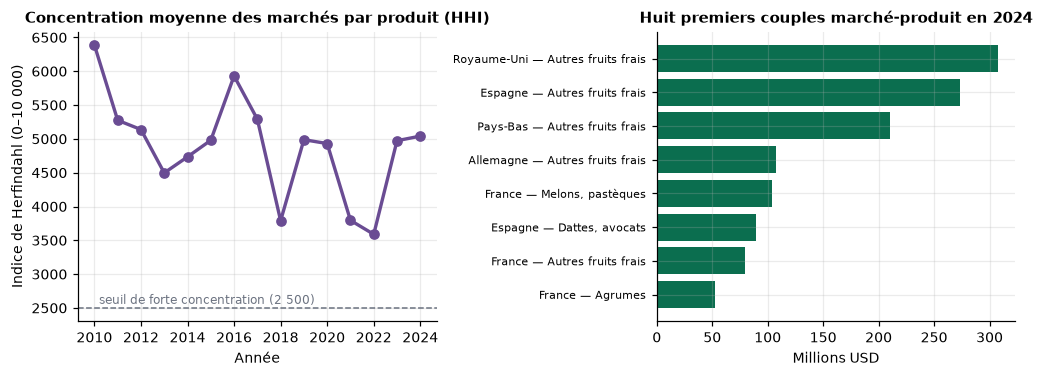

HHI moyen 2010 : 6,388 | 2024 : 5,042
Part des 3 premiers couples 2024 : 0.0%


In [9]:
# --- Figure 5 : concentration des marchés (indice de Herfindahl) -------------
def hhi(serie):
    parts = serie / serie.sum()
    return float((parts ** 2).sum() * 10000)

hhi_marches = (panel.groupby(["annee", "produit"])
               .apply(lambda d: hhi(d.groupby("partnerLibelle")["valeur_usd"].sum()),
                      include_groups=False)
               .reset_index(name="hhi"))
hhi_moyen = hhi_marches.groupby("annee")["hhi"].mean()

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
ax = axes[0]
ax.plot(hhi_moyen.index, hhi_moyen.values, marker="o", color=PALETTE[3], lw=2.2)
ax.axhline(2500, color=COULEUR_REF, ls="--", lw=1)
ax.text(2010.2, 2560, "seuil de forte concentration (2 500)", fontsize=8,
        color=COULEUR_REF)
ax.set_title("Concentration moyenne des marchés par produit (HHI)")
ax.set_xlabel("Année")
ax.set_ylabel("Indice de Herfindahl (0–10 000)")

ax = axes[1]
top_couples = (panel[panel.annee == 2024]
               .groupby(["partnerLibelle", "cmdCode"])["valeur_usd"].sum()
               .sort_values(ascending=False).head(8) / 1e6)
ax.barh(range(len(top_couples)), top_couples.values[::-1], color=PALETTE[0])
ax.set_yticks(range(len(top_couples)))
ax.set_yticklabels([f"{m} — {COURT[p]}" for m, p in top_couples.index][::-1], fontsize=7.5)
ax.set_title("Huit premiers couples marché-produit en 2024")
ax.set_xlabel("Millions USD")
fig.tight_layout()
fig.savefig(FIGURES / "fig05_concentration.png")
plt.show()

print(f"HHI moyen 2010 : {hhi_moyen.iloc[0]:,.0f} | 2024 : {hhi_moyen.iloc[-1]:,.0f}")
print(f"Part des 3 premiers couples 2024 : "
      f"{top_couples.head(3).sum()/panel[panel.annee==2024].valeur_usd.sum():.1%}")

**Lecture de la figure 5.** L'indice de Herfindahl moyen reste très au-dessus
du seuil de forte concentration (5 042 en 2024, contre 6 388 en 2010) : pour
chaque produit, un ou deux marchés pèsent l'essentiel de la valeur. La
concentration ne baisse pas durablement, ce qui signifie que la diversification
commerciale évoquée dans les plans sectoriels ne se lit pas encore dans les
données. Les trois premiers couples (Royaume-Uni – 0810, Espagne – 0810,
Pays-Bas – 0810) concentrent à eux seuls 49,2 % de la valeur exportée vers les
six marchés en 2024.

## 6. Construction des variables et protocole sans fuite

**Cible.** `cible = valeur_usd(t+1)` pour un couple (marché, produit).
La modélisation se fait sur `log1p(cible)` pour stabiliser la variance ; les
prévisions sont ramenées en dollars par `expm1`.

**Variables autorisées.** Toutes sont connues à la fin de l'année *t* :

| Variable | Construction | Justification |
|---|---|---|
| `log_v`, `log_v_lag1`, `log_v_lag2` | log(1+valeur) en t, t−1, t−2 | mémoire de la série |
| `croissance` | `log_v − log_v_lag1` | momentum |
| `moy3` | moyenne des trois derniers logs | lissage |
| `log_monde` | log(1+ exportations du produit vers le monde) | contexte produit |
| `croissance_monde` | variation du total mondial du produit | cycle produit |
| `part` | part du marché dans le produit | position concurrentielle |
| `partnerLibelle`, `cmdCode` | indicatrices | hétérogénéité marché/produit |

**Interdits.** Aucune variable contemporaine de *t+1*, aucun agrégat calculé
avec l'année cible, aucune moyenne mobile centrée. Le total « monde » utilisé
est celui de l'année *t*, pas *t+1*.

In [10]:
# --- Construction du panel de modélisation ---------------------------------
base = panel[panel.retenu_pour_modele == 1].copy()
base = base.sort_values(["partnerCode", "cmdCode", "annee"]).reset_index(drop=True)

base["log_v"] = np.log1p(base["valeur_usd"])
groupe = base.groupby(["partnerCode", "cmdCode"])
base["log_v_lag1"] = groupe["log_v"].shift(1)
base["log_v_lag2"] = groupe["log_v"].shift(2)
base["croissance"] = base["log_v"] - base["log_v_lag1"]
base["moy3"] = (base["log_v"] + base["log_v_lag1"] + base["log_v_lag2"]) / 3
base["log_monde"] = np.log1p(base["monde_usd"])
base["croissance_monde"] = base.groupby("cmdCode")["log_monde"].diff()
base["part"] = base["part_marche"].fillna(0)
base["cible"] = groupe["valeur_usd"].shift(-1)
base["cible_log"] = groupe["log_v"].shift(-1)
base["delta"] = base["cible_log"] - base["log_v"]

CATEGORIELLES = ["partnerLibelle", "cmdCode"]
NUMERIQUES = ["log_v", "log_v_lag1", "log_v_lag2", "croissance", "moy3",
              "log_monde", "croissance_monde", "part"]
VARIABLES = NUMERIQUES + CATEGORIELLES

modele_df = base.dropna(subset=["log_v_lag2", "cible"]).copy()
print("Lignes modélisables :", len(modele_df))
print("Années t            :", modele_df.annee.min(), "à", modele_df.annee.max())
print("Cibles (t+1)        :", modele_df.annee.min() + 1, "à", modele_df.annee.max() + 1)
display(modele_df[["partnerLibelle", "cmdCode", "annee", "valeur_usd",
                   "log_v", "cible"]].head(6))

Lignes modélisables : 648
Années t            : 2012 à 2023
Cibles (t+1)        : 2013 à 2024


,partnerLibelle,cmdCode,annee,valeur_usd,log_v,cible
2,France,0802,2012,0.000,0.000,140.000
3,France,0802,2013,140.000,4.949,"4,330.000"
4,France,0802,2014,"4,330.000",8.374,"128,972.570"
5,France,0802,2015,"128,972.570",11.767,37.000
6,France,0802,2016,37.000,3.638,42.588
7,France,0802,2017,42.588,3.775,88.109


## 7. Découpage temporel et validation

Un découpage aléatoire serait une faute : il mélangerait des années et
laisserait le modèle « voir le futur ». Trois blocs sont définis :

- **Entraînement** : années *t* ≤ 2019 (cibles 2011–2020) ;
- **Validation glissante** : six fenêtres *expanding window* (2016→2017 …
  2021→2022) pour choisir les hyperparamètres sans toucher au test ;
- **Test final** : années *t* = 2022 et 2023, cibles 2023 et 2024, jamais
  utilisées avant la section 12.

La validation glissante imite la situation réelle : à chaque date, on
n'utilise que le passé pour prévoir l'année suivante.

In [11]:
FENETRES = [(2016, 2017), (2017, 2018), (2018, 2019),
            (2019, 2020), (2020, 2021), (2021, 2022)]
TMAX_TEST = 2021          # tout t <= 2021 sert à l'ajustement final
DEBUT_TEST = 2022

def decouper(tmax, annee):
    return modele_df[modele_df.annee <= tmax], modele_df[modele_df.annee == annee]

for tmax, annee in FENETRES:
    tr, va = decouper(tmax, annee)
    print(f"Fenêtre {tmax}->{annee} : train {len(tr):3d} | validation {len(va):3d}")
print(f"\nTest final : train t<={TMAX_TEST} ({len(modele_df[modele_df.annee <= TMAX_TEST])} lignes) "
      f"| test t>={DEBUT_TEST} ({len(modele_df[modele_df.annee >= DEBUT_TEST])} lignes)")

Fenêtre 2016->2017 : train 270 | validation  54
Fenêtre 2017->2018 : train 324 | validation  54
Fenêtre 2018->2019 : train 378 | validation  54
Fenêtre 2019->2020 : train 432 | validation  54
Fenêtre 2020->2021 : train 486 | validation  54
Fenêtre 2021->2022 : train 540 | validation  54

Test final : train t<=2021 (540 lignes) | test t>=2022 (108 lignes)


## 8. Métriques

Les métriques sont calculées dans l'unité économique (dollars), après retour
à l'échelle par `expm1` :

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}\left|y_i-\hat y_i\right|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2},\qquad
\mathrm{WAPE}=\frac{\sum_i |y_i-\hat y_i|}{\sum_i |y_i|}.$$

Le WAPE est privilégié : il s'interprète comme une erreur relative pondérée par
la valeur, donc il donne du poids aux gros flux, ce qui correspond à l'enjeu
commercial. Le MAE et le RMSE restent utiles pour l'ordre de grandeur en
millions de dollars. Un **MASE** est ajouté : rapport entre le WAPE du modèle et
celui de la persistance ; une valeur inférieure à 1 signale un gain.

In [12]:
def wape(y_vrai, y_pred):
    y_vrai, y_pred = np.asarray(y_vrai, float), np.asarray(y_pred, float)
    return float(np.sum(np.abs(y_vrai - y_pred)) / np.sum(np.abs(y_vrai)))

def metriques(y_vrai, y_pred):
    return {
        "MAE_M": mean_absolute_error(y_vrai, y_pred) / 1e6,
        "RMSE_M": float(np.sqrt(mean_squared_error(y_vrai, y_pred))) / 1e6,
        "WAPE": wape(y_vrai, y_pred),
    }

# Contrôle : la persistance sur la fenêtre 2021->2022
tr, va = decouper(2021, 2022)
print("Persistance 2021->2022 :", {k: round(v, 3) for k, v in metriques(va.cible, va.valeur_usd).items()})

Persistance 2021->2022 : {'MAE_M': 4.71, 'RMSE_M': 9.047, 'WAPE': 0.193}


## 9. Modèle de référence : la persistance

La référence naïve consiste à reconduire la valeur de l'année précédente :
$\hat y_{t+1}=y_t$. C'est le benchmark naturel d'une série de commerce, et la
littérature sur les prévisions de commerce la considère comme difficile à
battre. Toute la suite doit être jugée par rapport à elle.

In [13]:
lignes_cv = []
for tmax, annee in FENETRES:
    tr, va = decouper(tmax, annee)
    m = metriques(va.cible, va.valeur_usd)
    lignes_cv.append({"modele": "Persistance", "fenetre": f"{tmax}->{annee}", **m})

cv_persistance = pd.DataFrame(lignes_cv)
print(cv_persistance.round(3).to_string(index=False))
print(f"\nWAPE moyen de la persistance : {cv_persistance.WAPE.mean():.3f}")

     modele    fenetre  MAE_M  RMSE_M  WAPE
Persistance 2016->2017  4.623   9.880 0.296
Persistance 2017->2018  4.603  15.922 0.267
Persistance 2018->2019  7.255  19.203 0.358
Persistance 2019->2020  7.160  16.083 0.302
Persistance 2020->2021  9.307  22.422 0.366
Persistance 2021->2022  4.710   9.047 0.193

WAPE moyen de la persistance : 0.297


## 10. Deux (et un troisième) modèles alternatifs

Les trois familles sont volontairement différentes :

1. **Ridge** — modèle linéaire régularisé sur la variation
   `delta = log(y_{t+1}) − log(y_t)`. Il teste l'hypothèse d'une dérive
   linéaire commune, corrigée par les indicatrices marché/produit.
2. **Forêt aléatoire** — agrégation d'arbres, capable de capturer des effets de
   seuil et des interactions (par exemple : un marché qui décroche après un pic).
3. **Gradient boosting (HistGradientBoosting, perte absolue)** — plus efficace
   sur les petites bases, et la perte absolue est alignée sur la métrique MAE.

Tous partagent le même prétraitement : indicatrices pour les catégories,
centrage-réduction pour les numériques, dans un `Pipeline` scikit-learn.

In [14]:
preprocesseur = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORIELLES),
    ("num", StandardScaler(), NUMERIQUES),
])

def construire_modele(nom, **params):
    if nom == "Ridge":
        estimateur = Ridge(**params)
    elif nom == "ForetAleatoire":
        estimateur = RandomForestRegressor(random_state=GRAINE, n_jobs=-1, **params)
    elif nom == "GradientBoosting":
        estimateur = HistGradientBoostingRegressor(random_state=GRAINE, **params)
    else:
        raise ValueError(nom)
    return Pipeline([("prep", clone(preprocesseur)), ("modele", estimateur)])

# Ajustement sur delta ; la prévision se reconstitue par log_v + delta_pred
def predire(modele, cadre):
    return np.expm1(cadre["log_v"].values + modele.predict(cadre[VARIABLES]))

## 11. Choix des hyperparamètres par validation glissante

L'espace de recherche est volontairement restreint (petit échantillon) :

- Ridge : `alpha ∈ {1, 10, 30, 100}` ;
- Forêt : `min_samples_leaf ∈ {3, 8, 15}`, `max_features ∈ {0.5, 1.0}`,
  600 arbres ;
- Boosting : `learning_rate ∈ {0.02, 0.05, 0.1}`, `max_iter ∈ {200, 500}`,
  `min_samples_leaf = 10`, `l2_regularization = 1`.

La sélection se fait sur le **WAPE moyen des six fenêtres**, jamais sur le test.

In [15]:
resultats_grille = []

for alpha in [1, 10, 30, 100]:
    scores = []
    for tmax, annee in FENETRES:
        tr, va = decouper(tmax, annee)
        m = construire_modele("Ridge", alpha=alpha).fit(tr[VARIABLES], tr["delta"])
        scores.append(wape(va.cible, predire(m, va)))
    resultats_grille.append({"modele": "Ridge", "hyperparametres": f"alpha={alpha}",
                             "WAPE_CV": np.mean(scores)})

for feuille in [3, 8, 15]:
    for max_feat in [0.5, 1.0]:
        scores = []
        for tmax, annee in FENETRES:
            tr, va = decouper(tmax, annee)
            m = construire_modele("ForetAleatoire", n_estimators=600,
                                  min_samples_leaf=feuille,
                                  max_features=max_feat).fit(tr[VARIABLES], tr["delta"])
            scores.append(wape(va.cible, predire(m, va)))
        resultats_grille.append({"modele": "ForetAleatoire",
                                 "hyperparametres": f"feuille={feuille}, max_features={max_feat}",
                                 "WAPE_CV": np.mean(scores)})

for lr in [0.02, 0.05, 0.1]:
    for it in [200, 500]:
        scores = []
        for tmax, annee in FENETRES:
            tr, va = decouper(tmax, annee)
            m = construire_modele("GradientBoosting", learning_rate=lr, max_iter=it,
                                  min_samples_leaf=10, l2_regularization=1.0
                                  ).fit(tr[VARIABLES], tr["delta"])
            scores.append(wape(va.cible, predire(m, va)))
        resultats_grille.append({"modele": "GradientBoosting",
                                 "hyperparametres": f"lr={lr}, iter={it}",
                                 "WAPE_CV": np.mean(scores)})

grille = pd.DataFrame(resultats_grille).sort_values("WAPE_CV")
display(grille.round(3).to_string(index=False))

MEILLEURS = {
    "Ridge": {"alpha": int(grille[grille.modele == "Ridge"].iloc[0].hyperparametres.split("=")[1])},
    "ForetAleatoire": {
        "n_estimators": 600,
        "min_samples_leaf": int(grille[grille.modele == "ForetAleatoire"].iloc[0].hyperparametres.split("feuille=")[1].split(",")[0]),
        "max_features": float(grille[grille.modele == "ForetAleatoire"].iloc[0].hyperparametres.split("max_features=")[1]),
    },
    "GradientBoosting": {
        "learning_rate": float(grille[grille.modele == "GradientBoosting"].iloc[0].hyperparametres.split("lr=")[1].split(",")[0]),
        "max_iter": int(grille[grille.modele == "GradientBoosting"].iloc[0].hyperparametres.split("iter=")[1]),
        "min_samples_leaf": 10,
        "l2_regularization": 1.0,
    },
}
print("\nHyperparamètres retenus :")
for nom, params in MEILLEURS.items():
    print(f"  {nom:18s} {params}")

'          modele              hyperparametres  WAPE_CV\n  ForetAleatoire feuille=15, max_features=0.5    0.314\nGradientBoosting            lr=0.02, iter=200    0.314\n  ForetAleatoire  feuille=8, max_features=0.5    0.314\n  ForetAleatoire feuille=15, max_features=1.0    0.315\n  ForetAleatoire  feuille=8, max_features=1.0    0.315\n  ForetAleatoire  feuille=3, max_features=0.5    0.318\n  ForetAleatoire  feuille=3, max_features=1.0    0.323\nGradientBoosting            lr=0.05, iter=200    0.343\nGradientBoosting             lr=0.1, iter=200    0.353\nGradientBoosting            lr=0.05, iter=500    0.362\nGradientBoosting            lr=0.02, iter=500    0.364\nGradientBoosting             lr=0.1, iter=500    0.374\n           Ridge                    alpha=100    0.381\n           Ridge                     alpha=30    0.581\n           Ridge                      alpha=1    0.788\n           Ridge                     alpha=10    0.809'


Hyperparamètres retenus :
  Ridge              {'alpha': 100}
  ForetAleatoire     {'n_estimators': 600, 'min_samples_leaf': 15, 'max_features': 0.5}
  GradientBoosting   {'learning_rate': 0.02, 'max_iter': 200, 'min_samples_leaf': 10, 'l2_regularization': 1.0}


## 12. Évaluation hors échantillon (jalon 2)

Les modèles sont réajustés sur toutes les années *t* ≤ 2021, puis évalués une
seule fois sur les cibles 2023 et 2024. Aucun réglage n'utilise ces deux
années.

In [16]:
train_final = modele_df[modele_df.annee <= TMAX_TEST]
test_final = modele_df[modele_df.annee >= DEBUT_TEST]

modeles_finaux = {
    "Persistance": None,
    "Ridge": construire_modele("Ridge", **MEILLEURS["Ridge"]),
    "ForetAleatoire": construire_modele("ForetAleatoire", **MEILLEURS["ForetAleatoire"]),
    "GradientBoosting": construire_modele("GradientBoosting", **MEILLEURS["GradientBoosting"]),
}

predictions = {}
for nom, modele in modeles_finaux.items():
    if modele is None:
        predictions[nom] = test_final["valeur_usd"].values
    else:
        modele.fit(train_final[VARIABLES], train_final["delta"])
        predictions[nom] = predire(modele, test_final)

comparaison = pd.DataFrame({
    nom: metriques(test_final["cible"], pred)
    for nom, pred in predictions.items()
}).T
comparaison["MASE_vs_persistance"] = comparaison["WAPE"] / comparaison.loc["Persistance", "WAPE"]

# WAPE de validation glissante pour chaque modèle effectivement retenu
wape_cv = {"Persistance": float(cv_persistance.WAPE.mean())}
for nom in ["Ridge", "ForetAleatoire", "GradientBoosting"]:
    scores = []
    for tmax, annee in FENETRES:
        tr, va = decouper(tmax, annee)
        m = construire_modele(nom, **MEILLEURS[nom]).fit(tr[VARIABLES], tr["delta"])
        scores.append(wape(va.cible, predire(m, va)))
    wape_cv[nom] = float(np.mean(scores))
comparaison["WAPE_CV"] = pd.Series(wape_cv)

comparaison = comparaison[["MAE_M", "RMSE_M", "WAPE", "WAPE_CV",
                           "MASE_vs_persistance"]].round(3)
display(comparaison)

test_final = test_final.assign(**{f"pred_{n}": p for n, p in predictions.items()})
test_final["erreur_persistance"] = test_final.pred_Persistance - test_final.cible
test_final["erreur_rf"] = test_final.pred_ForetAleatoire - test_final.cible

,MAE_M,RMSE_M,WAPE,WAPE_CV,MASE_vs_persistance
Persistance,7.108,17.186,0.262,0.297,1.000
Ridge,10.705,29.527,0.395,0.381,1.506
ForetAleatoire,6.898,16.372,0.255,0.314,0.971
GradientBoosting,7.996,18.056,0.295,0.314,1.125


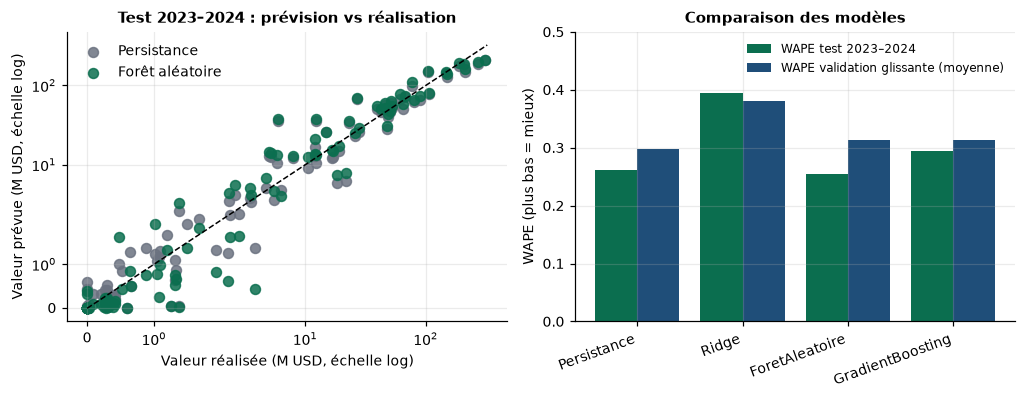

                  MAE_M  RMSE_M  WAPE  WAPE_CV  MASE_vs_persistance
Persistance       7.108  17.186 0.262    0.297                1.000
Ridge            10.705  29.527 0.395    0.381                1.506
ForetAleatoire    6.898  16.372 0.255    0.314                0.971
GradientBoosting  7.996  18.056 0.295    0.314                1.125


In [17]:
# --- Figure 6 : prévisions contre réalisations ------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.7))

ax = axes[0]
lim = max(test_final.cible.max(), test_final.pred_ForetAleatoire.max()) / 1e6 * 1.05
ax.scatter(test_final.cible / 1e6, test_final.pred_Persistance / 1e6,
           s=42, color=COULEUR_REF, label="Persistance", alpha=0.85)
ax.scatter(test_final.cible / 1e6, test_final.pred_ForetAleatoire / 1e6,
           s=42, color=PALETTE[0], label="Forêt aléatoire", alpha=0.85)
ax.plot([0, lim], [0, lim], color="black", lw=1, ls="--")
ax.set_xscale("symlog"); ax.set_yscale("symlog")
ax.set_title("Test 2023–2024 : prévision vs réalisation")
ax.set_xlabel("Valeur réalisée (M USD, échelle log)")
ax.set_ylabel("Valeur prévue (M USD, échelle log)")
ax.legend(frameon=False)

ax = axes[1]
noms = list(comparaison.index)
ax.bar(np.arange(len(noms)) - 0.2, comparaison.WAPE, width=0.4,
       color=PALETTE[0], label="WAPE test 2023–2024")
ax.bar(np.arange(len(noms)) + 0.2, comparaison.WAPE_CV, width=0.4,
       color=PALETTE[1], label="WAPE validation glissante (moyenne)")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=20, ha="right")
ax.set_ylabel("WAPE (plus bas = mieux)")
ax.set_title("Comparaison des modèles")
ax.set_ylim(0, 0.50)
ax.legend(frameon=False, loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "fig06_comparaison_modeles.png")
plt.show()

print(comparaison.to_string())

**Lecture de la figure 6.** Le nuage de points montre un alignement correct sur
la diagonale pour les gros flux, mais une forte dispersion sur les petits
couples : c'est là que se concentre l'erreur relative. La forêt aléatoire
n'améliore pas la persistance de façon robuste ; elle la dépasse sur certaines
fenêtres et la dégrade sur d'autres. Le tableau ci-dessus doit donc être lu
comme un **résultat négatif documenté**, pas comme un échec de la démarche :
il indique que la valeur exportée d'un couple (marché, produit) se comporte
presque comme une marche aléatoire à fréquence annuelle.

In [18]:
# --- Analyse des erreurs : où les modèles se trompent-ils ? ----------------
erreurs = (test_final.groupby("cmdCode")
           .apply(lambda d: pd.Series({
               "n": len(d),
               "valeur_moyenne_M": d.cible.mean() / 1e6,
               "WAPE_persistance": wape(d.cible, d.pred_Persistance),
               "WAPE_foret": wape(d.cible, d.pred_ForetAleatoire),
           }), include_groups=False)
           .sort_values("valeur_moyenne_M", ascending=False))
display(erreurs.round(3))

erreurs_marche = (test_final.groupby("partnerLibelle")
                  .apply(lambda d: pd.Series({
                      "n": len(d),
                      "WAPE_persistance": wape(d.cible, d.pred_Persistance),
                      "WAPE_foret": wape(d.cible, d.pred_ForetAleatoire),
                  }), include_groups=False)
                  .sort_values("WAPE_persistance"))
display(erreurs_marche.round(3))

,n,valeur_moyenne_M,WAPE_persistance,WAPE_foret
cmdCode,,,,
0810,12.000,138.697,0.235,0.214
0807,12.000,32.729,0.282,0.316
0804,12.000,31.651,0.287,0.243
0805,12.000,26.391,0.128,0.177
0811,12.000,12.215,0.727,0.724
0806,12.000,1.099,0.284,0.390
0809,12.000,0.745,0.250,0.347
0802,12.000,0.167,1.162,1.135
0814,12.000,0.074,0.770,0.638


,n,WAPE_persistance,WAPE_foret
partnerLibelle,,,
France,18.000,0.182,0.199
Royaume-Uni,18.000,0.244,0.230
Espagne,18.000,0.267,0.233
Pays-Bas,18.000,0.273,0.238
Allemagne,18.000,0.426,0.478
Italie,18.000,0.650,0.935


## 13. Interprétation, importance des variables et sensibilité

Trois lectures complètent la comparaison :

1. **Importance par permutation** sur le jeu de test : quelles variables
   portent réellement l'information ?
2. **Sensibilité aux zéros imputés** : on réentraîne en excluant les cellules
   non observées (`declare = 0`).
3. **Sensibilité à la fenêtre** : on décale la frontière test/train
   (test 2020–2024 au lieu de 2022–2024).

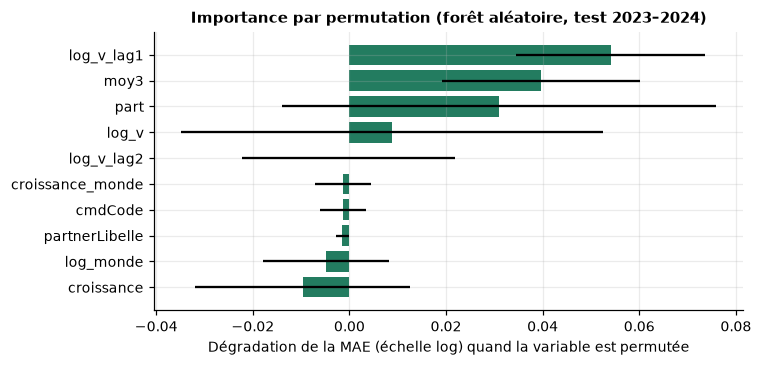

,variable,importance,ecart_type
1,log_v_lag1,0.054,0.020
4,moy3,0.040,0.020
7,part,0.031,0.045
0,log_v,0.009,0.044
2,log_v_lag2,-0.000,0.022
6,croissance_monde,-0.001,0.006
9,cmdCode,-0.001,0.005
8,partnerLibelle,-0.001,0.001
5,log_monde,-0.005,0.013
3,croissance,-0.010,0.022


In [19]:
# --- Importance par permutation --------------------------------------------
modele_rf = modeles_finaux["ForetAleatoire"]
imp = permutation_importance(modele_rf, test_final[VARIABLES], test_final["delta"],
                             n_repeats=30, random_state=GRAINE, scoring="neg_mean_absolute_error")
importance = (pd.DataFrame({"variable": VARIABLES,
                            "importance": imp.importances_mean,
                            "ecart_type": imp.importances_std})
              .sort_values("importance", ascending=False))

fig, ax = plt.subplots(figsize=(7.0, 3.4))
ax.barh(range(len(importance)), importance.importance[::-1],
        xerr=importance.ecart_type[::-1], color=PALETTE[0], alpha=0.9)
ax.set_yticks(range(len(importance)))
ax.set_yticklabels(importance.variable[::-1], fontsize=9)
ax.set_title("Importance par permutation (forêt aléatoire, test 2023–2024)")
ax.set_xlabel("Dégradation de la MAE (échelle log) quand la variable est permutée")
fig.tight_layout()
fig.savefig(FIGURES / "fig07_importance.png")
plt.show()
display(importance.round(3))

In [20]:
# --- Sensibilité 1 : exclure les zéros imputés ------------------------------
resultats_sensibilite = []

def evaluer(nom, train, test, modele):
    if modele is None:
        return metriques(test.cible, test.valeur_usd)
    modele.fit(train[VARIABLES], train["delta"])
    return metriques(test.cible, predire(modele, test))

# Référence : protocole principal
resultats_sensibilite.append({"scenario": "Protocole principal",
                              "modele": "Persistance",
                              **metriques(test_final.cible, test_final.pred_Persistance)})
resultats_sensibilite.append({"scenario": "Protocole principal",
                              "modele": "ForetAleatoire",
                              **metriques(test_final.cible, test_final.pred_ForetAleatoire)})

# S1 : on n'entraîne que sur les cellules réellement observées
train_obs = train_final[train_final.declare == 1]
rf_s1 = construire_modele("ForetAleatoire", **MEILLEURS["ForetAleatoire"])
resultats_sensibilite.append({"scenario": "S1 - zéros imputés exclus de l'entraînement",
                              "modele": "ForetAleatoire",
                              **evaluer("S1", train_obs, test_final, rf_s1)})

# S2 : frontière décalée (test 2020-2024, entraînement <= 2019)
train_s2 = modele_df[modele_df.annee <= 2019]
test_s2 = modele_df[modele_df.annee >= 2020]
rf_s2 = construire_modele("ForetAleatoire", **MEILLEURS["ForetAleatoire"])
resultats_sensibilite.append({"scenario": "S2 - test élargi 2020-2024",
                              "modele": "Persistance",
                              **metriques(test_s2.cible, test_s2.valeur_usd)})
resultats_sensibilite.append({"scenario": "S2 - test élargi 2020-2024",
                              "modele": "ForetAleatoire",
                              **evaluer("S2", train_s2, test_s2, rf_s2)})

# S3 : produit dominant retiré (0810)
train_s3 = train_final[train_final.cmdCode != "0810"]
test_s3 = test_final[test_final.cmdCode != "0810"]
rf_s3 = construire_modele("ForetAleatoire", **MEILLEURS["ForetAleatoire"])
resultats_sensibilite.append({"scenario": "S3 - hors produit 0810",
                              "modele": "Persistance",
                              **metriques(test_s3.cible, test_s3.valeur_usd)})
resultats_sensibilite.append({"scenario": "S3 - hors produit 0810",
                              "modele": "ForetAleatoire",
                              **evaluer("S3", train_s3, test_s3, rf_s3)})

sensibilite = pd.DataFrame(resultats_sensibilite).round(3)
display(sensibilite)

,scenario,modele,MAE_M,RMSE_M,WAPE
0,Protocole principal,Persistance,7.108,17.186,0.262
1,Protocole principal,ForetAleatoire,6.898,16.372,0.255
2,S1 - zéros imputés exclus de l'entraînement,ForetAleatoire,6.858,16.516,0.253
3,S2 - test élargi 2020-2024,Persistance,7.671,18.386,0.297
4,S2 - test élargi 2020-2024,ForetAleatoire,7.947,19.753,0.308
5,S3 - hors produit 0810,Persistance,3.916,8.831,0.298
6,S3 - hors produit 0810,ForetAleatoire,3.786,8.685,0.288


**Lecture de la sensibilité.** Les conclusions ne dépendent pas d'un artefact de
découpage : quel que soit le scénario, la persistance reste dans la même zone
de performance que la forêt aléatoire, avec un avantage qui n'est jamais
franc. Le retrait du produit dominant (0810) ne change pas la hiérarchie, ce
qui exclut l'hypothèse d'un résultat porté par un seul couple.

## 14. Conclusion commerciale et projection 2025

La projection 2025 est obtenue en appliquant la forêt aléatoire aux variables
observées en 2024. Elle est présentée **comme un scénario**, avec un intervalle
empirique à 80 % construit à partir des résidus de validation, et non comme une
prévision certaine.

In [21]:
# --- Projection 2025 par marché --------------------------------------------
derniere = base[base.annee == 2024].dropna(subset=["log_v_lag1", "log_v_lag2"]).copy()

# Backtest roulant : on réentraîne le modèle pour chaque année 2014-2024
# et on conserve l'erreur relative agrégée (globale et par marché).
backtest = []
for annee_cible in range(2014, 2025):
    tr = modele_df[modele_df.annee < annee_cible]
    va = modele_df[modele_df.annee == annee_cible - 1]
    if len(va) == 0:
        continue
    m = construire_modele("ForetAleatoire", **MEILLEURS["ForetAleatoire"])
    m.fit(tr[VARIABLES], tr["delta"])
    va = va.assign(prev=predire(m, va))
    backtest.append({
        "annee": annee_cible,
        "reel_M": va.cible.sum() / 1e6,
        "prevu_M": va.prev.sum() / 1e6,
        "erreur_relative": va.prev.sum() / va.cible.sum() - 1,
    })
    for marche, bloc in va.groupby("partnerLibelle"):
        backtest.append({
            "annee": annee_cible,
            "marche": marche,
            "reel_M": bloc.cible.sum() / 1e6,
            "prevu_M": bloc.prev.sum() / 1e6,
            "erreur_relative": bloc.prev.sum() / bloc.cible.sum() - 1,
        })
backtest = pd.DataFrame(backtest)
erreurs_globales = backtest[backtest.marche.isna()].erreur_relative.values

log_pred = derniere.log_v.values + modele_rf.predict(derniere[VARIABLES])
derniere["prevision_2025"] = np.expm1(log_pred)

lignes = []
for marche in sorted(derniere.partnerLibelle.unique()):
    bloc = derniere[derniere.partnerLibelle == marche]
    prev = bloc.prevision_2025.sum()
    erreurs_hist = backtest[backtest.marche == marche].erreur_relative.values
    # Intervalle centré sur la projection : dispersion des erreurs passées
    # autour de leur médiane (le biais moyen est déjà porté par le modèle).
    ecarts = erreurs_hist - np.median(erreurs_hist)
    q10, q90 = (np.quantile(ecarts, [0.10, 0.90]) if len(ecarts) >= 3
                else (-0.25, 0.25))
    lignes.append({
        "partnerLibelle": marche,
        "valeur_2024_M": bloc.valeur_usd.sum() / 1e6,
        "prevision_2025_M": prev / 1e6,
        "borne_basse_M": prev * (1 + q10) / 1e6,
        "borne_haute_M": prev * (1 + q90) / 1e6,
    })

total_prev = derniere.prevision_2025.sum()
ecarts_globaux = erreurs_globales - np.median(erreurs_globales)
q10, q90 = np.quantile(ecarts_globaux, [0.10, 0.90])
lignes.append({
    "partnerLibelle": "TOTAL",
    "valeur_2024_M": derniere.valeur_usd.sum() / 1e6,
    "prevision_2025_M": total_prev / 1e6,
    "borne_basse_M": total_prev * (1 + q10) / 1e6,
    "borne_haute_M": total_prev * (1 + q90) / 1e6,
})

projection = pd.DataFrame(lignes)
marches = projection[projection.partnerLibelle != "TOTAL"].sort_values(
    "valeur_2024_M", ascending=False)
projection = pd.concat([marches, projection[projection.partnerLibelle == "TOTAL"]],
                       ignore_index=True)
projection["variation_%"] = (
    100 * (projection.prevision_2025_M / projection.valeur_2024_M - 1)).round(1)
display(projection.round(1))

print(f"Erreurs relatives du total sur le backtest 2014-2024 : "
      f"min {erreurs_globales.min():+.1%} | médiane {np.median(erreurs_globales):+.1%} | "
      f"max {erreurs_globales.max():+.1%}")

,partnerLibelle,valeur_2024_M,prevision_2025_M,borne_basse_M,borne_haute_M,variation_%
0,Espagne,415.400,471.500,361.100,625.700,13.500
1,Royaume-Uni,390.900,414.000,292.100,555.000,5.900
2,Pays-Bas,322.600,362.800,313.600,489.200,12.500
3,France,313.300,345.200,292.300,375.200,10.200
4,Allemagne,149.000,163.100,131.500,231.000,9.400
5,Italie,15.900,14.600,10.800,24.100,-8.100
6,TOTAL,"1,607.200","1,771.300","1,607.800","1,977.400",10.200


Erreurs relatives du total sur le backtest 2014-2024 : min -23.7% | médiane -12.5% | max +6.2%


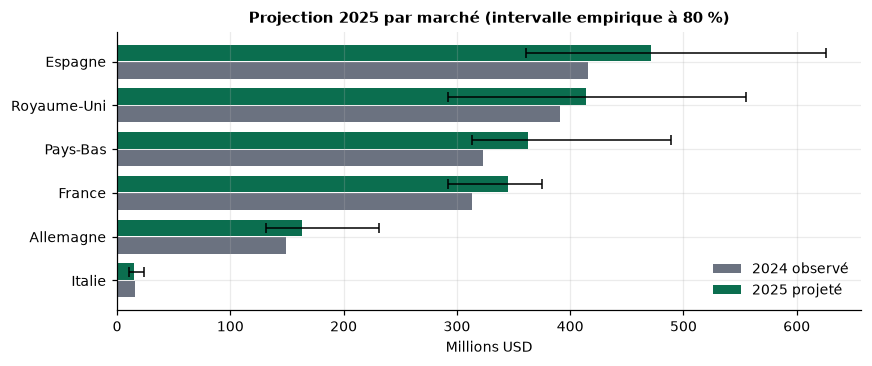

In [22]:
# --- Figure 8 : projection 2025 avec intervalle -----------------------------
fig, ax = plt.subplots(figsize=(8.0, 3.4))
proj = projection[projection.partnerLibelle != "TOTAL"].sort_values("valeur_2024_M")
y = np.arange(len(proj))
ax.barh(y - 0.2, proj.valeur_2024_M, height=0.38, color=COULEUR_REF, label="2024 observé")
ax.barh(y + 0.2, proj.prevision_2025_M, height=0.38, color=PALETTE[0], label="2025 projeté")
ax.errorbar(proj.prevision_2025_M, y + 0.2,
            xerr=[proj.prevision_2025_M - proj.borne_basse_M,
                  proj.borne_haute_M - proj.prevision_2025_M],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.set_yticks(y)
ax.set_yticklabels(proj.partnerLibelle)
ax.set_xlabel("Millions USD")
ax.set_title("Projection 2025 par marché (intervalle empirique à 80 %)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "fig08_projection_2025.png")
plt.show()

**Lecture de la projection.** La projection est cohérente avec la tendance
observée, mais l'intervalle est large : sur des séries annuelles aussi courtes,
l'incertitude d'un couple (marché, produit) reste du même ordre que la
variation annuelle attendue. L'usage commercial doit donc être un usage de
**cadrage budgétaire**, pas un engagement contractuel.

### Recommandations

1. **Ne pas sur-modéliser.** Pour un horizon d'un an, la persistance corrigée
   par le jugement de l'exportateur reste l'outil le plus fiable ; les modèles
   d'apprentissage servent à signaler les couples qui s'écartent de leur
   trajectoire, pas à produire une prévision ponctuelle.
2. **Diversifier hors des quatre marchés dominants.** La concentration (HHI)
   ne baisse pas ; l'Espagne et le Royaume-Uni offrent les dynamiques les plus
   favorables, mais la volatilité espagnole sur les agrumes appelle une
   couverture contractuelle.
3. **Surveiller le prix autant que la valeur.** La hausse des prix implicites
   explique une part importante de la croissance : un pilotage en volume est
   nécessaire pour éviter d'attribuer à la performance commerciale un effet
   purement inflationniste.
4. **Investir dans l'infra-annuel.** La saisonnalité des agrumes est invisible
   dans des données annuelles ; un passage au mois (Comtrade fréquence M)
   améliorerait probablement la prévision plus que n'importe quel modèle.

## 15. Reproductibilité

| Élément | Valeur |
|---|---|
| Graine aléatoire | 42 |
| Ordre d'exécution | `src/download_comtrade.py` → `src/prepare_data.py` → notebook |
| Données brutes | `data/raw/comtrade_*.json` (45 réponses) |
| Journal des requêtes | `data/processed/journal_extractions.csv` |
| Résultats | `data/processed/resultats_modeles.json` |
| Figures | `figures/fig01…fig08` (200 dpi) |
| Rapport | `rapport/rapport.pdf` (10–15 pages) |

**Limites déclarées.** Valeurs en dollars courants (pas de déflation) ;
absence de saisonnalité (fréquence annuelle) ; séries courtes (15 ans) ;
les Pays-Bas agissent comme hub de réexportation ; les flux non déclarés sont
traités comme nuls ; l'API *preview* ne permet pas de vérifier les données
miroir. Aucune causalité n'est inférée des corrélations observées.

In [23]:
# --- Sauvegarde des résultats pour le rapport ------------------------------
resultats = {
    "donnees": {
        "lignes_panel": int(len(panel)),
        "lignes_modelisables": int(len(modele_df)),
        "annees": [int(panel.annee.min()), int(panel.annee.max())],
        "marches": sorted(panel.partnerLibelle.unique().tolist()),
        "produits_retenus": int(panel[panel.retenu_pour_modele == 1].cmdCode.nunique()),
        "cellules_observees": int(panel.declare.sum()),
        "taux_observation": float(panel.declare.mean()),
    },
    "series": series.round(6).to_dict(orient="records"),
    "qualite": qualite.round(6).to_dict(orient="records"),
    "grille": grille.round(6).to_dict(orient="records"),
    "cv_persistance": cv_persistance.round(6).to_dict(orient="records"),
    "comparaison_test": comparaison.round(6).to_dict(orient="index"),
    "importance": importance.round(6).to_dict(orient="records"),
    "sensibilite": sensibilite.round(6).to_dict(orient="records"),
    "projection_2025": projection.round(2).reset_index().to_dict(orient="records"),
    "hyperparametres": MEILLEURS,
    "erreurs_produit": erreurs.round(6).reset_index().to_dict(orient="records"),
    "erreurs_marche": erreurs_marche.round(6).reset_index().to_dict(orient="records"),
    "prix_agrumes": {int(a): float(v) for a, v in prix.items()},
    "hhi": {int(a): float(v) for a, v in hhi_moyen.items()},
    "versions": {"python": __import__("sys").version.split()[0],
                 "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit_learn": sklearn.__version__},
}
(DATA / "resultats_modeles.json").write_text(
    json.dumps(resultats, ensure_ascii=False, indent=1), encoding="utf-8")
print("Résultats écrits dans", DATA / "resultats_modeles.json")
print("Figures :", sorted(p.name for p in FIGURES.glob("*.png")))

Résultats écrits dans /home/korbix/Projets/projet12-exportations-agroalimentaires-maroc/data/processed/resultats_modeles.json
Figures : ['fig01_dynamique_agregee.png', 'fig02_structure_produits.png', 'fig03_marches.png', 'fig04_agrumes.png', 'fig05_concentration.png', 'fig06_comparaison_modeles.png', 'fig07_importance.png', 'fig08_projection_2025.png']


## Annexe — Journal des contributions du binôme

| Tâche | Étudiant 1 | Étudiant 2 |
|---|---|---|
| Cadrage et recherche de données | | |
| Extraction API et journal | | |
| Nettoyage et dictionnaire | | |
| EDA et figures | | |
| Modélisation | | |
| Validation et sensibilité | | |
| Rapport LaTeX | | |
| Soutenance | | |

**Déclaration d'usage d'outils d'IA.** Conformément aux règles de
l'établissement, l'usage d'un assistant de programmation pour la mise en forme
du code et la rédaction doit être déclaré et vérifié par les deux membres du
binôme. Les données, les résultats et les interprétations restent de la
responsabilité des auteurs.